# Kip handling-noise filter: proof of concept

A phone on a nightstand, in a pocket or under a pillow hears **itself**: fabric rubbing on the mic, the phone being
knocked or set down. Those spikes would otherwise be labelled and linked to wake-ups. **HandlingNet** is a small model
we trained ourselves (about 0.2 to 0.4M parameters) that flags phone-handling noise every 10 ms and removes it,
while leaving the room alone.

This notebook shows the data, the training, how it compares with a classic spectral noise gate, and what it does to
real recordings from our demo iPhone. **Every number is measured on audio the model never trained on.**

- Code: `ml/kipml/` (data, model, train, evaluate, infer, export, report) and `ml/README.md`
- Charts and before/after audio: `ml/reports/`
- To run it yourself: `cd ml && uv sync --group dev && uv run jupyter lab notebooks/handling_poc.ipynb`
  (or open it in VS Code with the `ml/.venv` kernel).

In [1]:
import json, sys
from pathlib import Path

ML = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "kipml").is_dir())
sys.path.insert(0, str(ML))

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio, Image, Markdown, display

from kipml import report                      # applies the chart style (validated palette)
from kipml.audio import AUDIO, HOP, RATE, read_wav
from kipml.data import load_sources, make_example
from kipml.evaluate import load_model
from kipml.model import enhance, count_params
%matplotlib inline

REPORTS = {name: ML / "reports" / name for name in ("handling-poc", "handling-gpu") if (ML / "reports" / name / "summary.json").exists()}
print("reports found:", ", ".join(REPORTS) or "none: run `uv run python -m kipml.report` first")

reports found: handling-poc


## 1. The data

Training examples are **mixed on the fly**: a 2 to 4 second slice of a night background, plus (75% of the time) a
slice of phone-handling noise at a random loudness (-5 to +20 dB against the background), then a random overall
gain. That turns a few minutes of recordings into unlimited, always-different examples.

**Labels**: a 10 ms frame counts as handling noise when the handling clip is louder there than its own quiet floor
by 8 dB and, for our venue takes, louder than the venue itself (90th percentile of the venue room tone plus 3 dB).
**Target**: the background plus the quiet parts of the take, so the model learns to remove the bursts, not the room.

Splits are by source file: three of our takes (`sleeve_03`, `pickup_01`, `pocket_02`), the last four placeholder
clips, ESC-50 fold 5 and the last 20% of the private room recordings are never trained on.

In [2]:
src = load_sources()
rows = []
for group, splits in (("handling", src["handling"]), ("background", src["background"])):
    for split, clips in splits.items():
        pools = clips if isinstance(clips, dict) else {"all": clips}
        for pool, cs in pools.items():
            secs = sum(len(c.x) for c in cs) / RATE
            rows.append(f"| {group} | {pool} | {split} | {len(cs)} | {secs:.0f} s |")
display(Markdown("| Kind | Source | Split | Clips | Audio |\n|---|---|---|---|---|\n" + "\n".join(rows)))

| Kind | Source | Split | Clips | Audio |
|---|---|---|---|---|
| handling | ours | train | 6 | 131 s |
| handling | synthetic | train | 20 | 100 s |
| handling | ours | test | 3 | 32 s |
| handling | synthetic | test | 4 | 20 s |
| background | all | train | 77 | 810 s |
| background | all | test | 17 | 184 s |

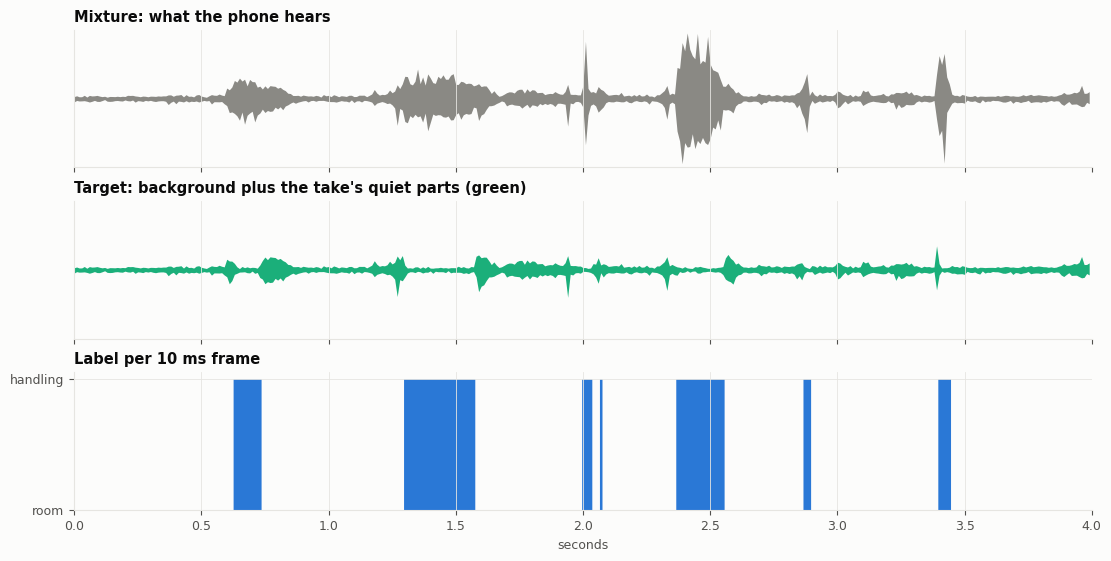

In [3]:
# One training example, exactly as the model sees it
rng = np.random.default_rng(11)
while True:
    mix, target, labels, has = make_example(rng, src, "train", seconds=4.0)
    if has and 0.05 < labels.mean() < 0.6:
        break
t = np.arange(len(mix)) / RATE
fig, axes = plt.subplots(3, 1, figsize=(11, 5.5), sharex=True, constrained_layout=True)
report._envelope(axes[0], mix, report.INPUT); axes[0].set_title("Mixture: what the phone hears"); axes[0].set_yticks([])
report._envelope(axes[1], target, report.TRUTH); axes[1].set_title("Target: background plus the take's quiet parts (green)"); axes[1].set_yticks([])
lim = np.abs(mix).max() * 1.05
for ax in axes[:2]:
    ax.set_ylim(-lim, lim)
axes[2].fill_between(np.arange(len(labels)) * HOP / RATE, 0, labels, color=report.MODEL, step="mid", linewidth=0)
axes[2].set_ylim(0, 1.05); axes[2].set_yticks([0, 1], ["room", "handling"]); axes[2].set_title("Label per 10 ms frame")
axes[2].set_xlabel("seconds")
plt.show()
display(Audio(mix, rate=RATE))

## 2. Training

The loss has two parts: how close the cleaned spectrogram is to the target (**suppression**), and how well the
model flags handling frames (**detection**). *Held-out* is a fixed set of mixtures built only from test sources.

**handling-poc**

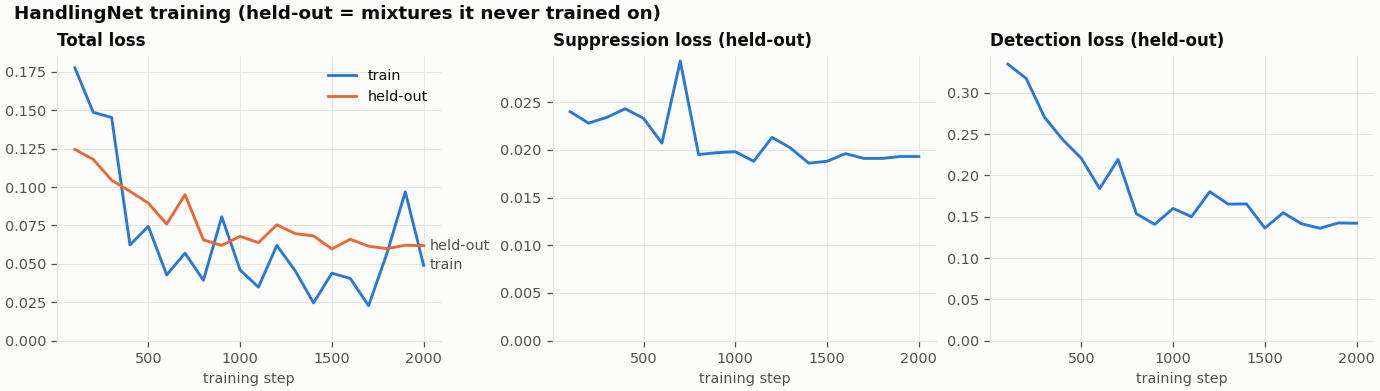

In [4]:
for name, folder in REPORTS.items():
    display(Markdown(f"**{name}**"))
    display(Image(filename=str(folder / "training.png")))

## 3. Against a classic spectral noise gate

A spectral gate estimates a steady noise floor per frequency and subtracts it. It is the standard tool for
"remove background noise", and the wrong tool here: handling noise is short and bursty, so a gate barely touches
it while still eating into the room. **SI-SDR improvement** measures how much closer the output gets to the target
(higher is better); the right-hand chart shows how much each method removes where there *is* handling noise and
where there is *not* (ideal: a lot, then nothing).

| Model | SI-SDR gain, model | SI-SDR gain, gate | Removed by model (handling / room) | Removed by gate (handling / room) | Detection P / R / F1 |
|---|---|---|---|---|---|
| handling-poc | +2.6 dB | -3.9 dB | 8.5 / 0.0 dB | 1.2 / 5.5 dB | 0.84 / 0.93 / 0.88 |

**handling-poc**

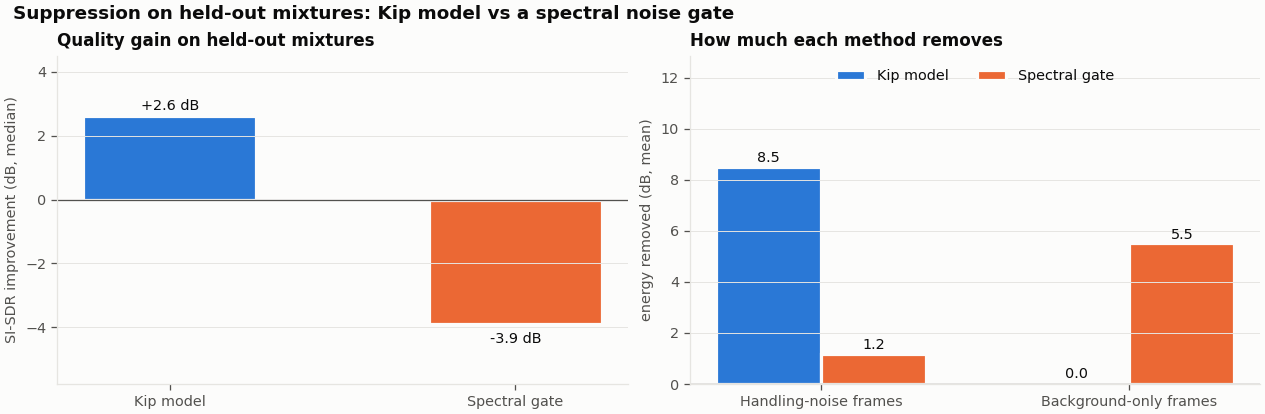

In [5]:
def row(name, s):
    e, d = s["energy_removed_db"], s["detection"]
    return (f"| {name} | {s['si_sdr_improvement_db']['model']:+.1f} dB | {s['si_sdr_improvement_db']['gate']:+.1f} dB | "
            f"{e['model_handling']:.1f} / {e['model_background']:.1f} dB | {e['gate_handling']:.1f} / {e['gate_background']:.1f} dB | "
            f"{d['precision']:.2f} / {d['recall']:.2f} / {d['f1']:.2f} |")
summaries = {name: json.loads((f / "summary.json").read_text()) for name, f in REPORTS.items()}
display(Markdown("| Model | SI-SDR gain, model | SI-SDR gain, gate | Removed by model (handling / room) | Removed by gate (handling / room) | Detection P / R / F1 |\n"
                 "|---|---|---|---|---|---|\n" + "\n".join(row(n, s) for n, s in summaries.items())))
for name, folder in REPORTS.items():
    display(Markdown(f"**{name}**")); display(Image(filename=str(folder / "suppression.png")))

## 4. One held-out mixture, with the true answer

One of our real drop takes (held out) mixed into a held-out background. Compare the model's output with the gate's
and with the target. Listen below: input, model, gate, target.

Model: **handling-poc**

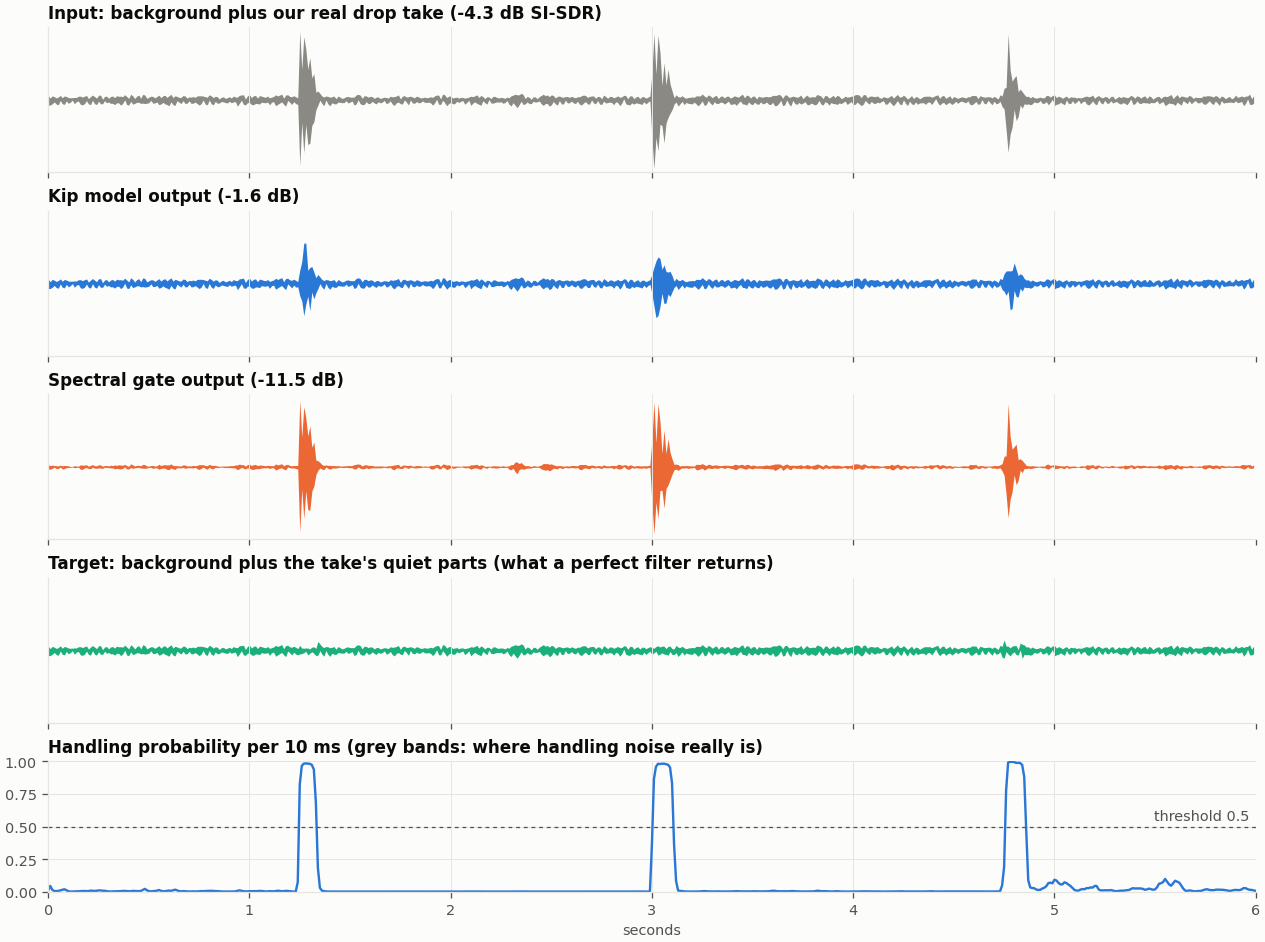

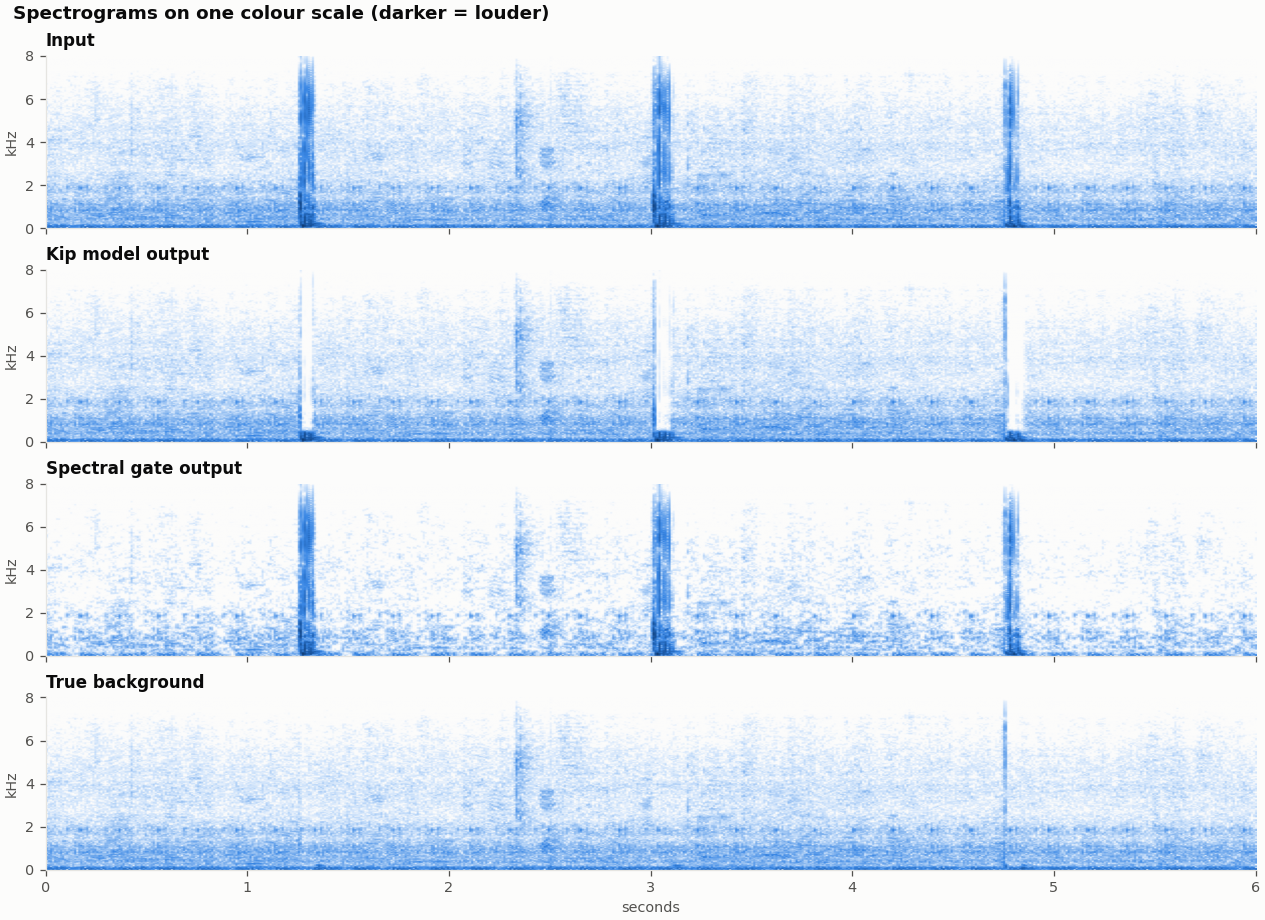

`mixture_input` ([file](../reports/handling-poc/audio/mixture_input.wav))

`mixture_kip` ([file](../reports/handling-poc/audio/mixture_kip.wav))

`mixture_gate` ([file](../reports/handling-poc/audio/mixture_gate.wav))

`mixture_true_background` ([file](../reports/handling-poc/audio/mixture_true_background.wav))

In [6]:
best = "handling-gpu" if "handling-gpu" in REPORTS else "handling-poc"
folder = REPORTS[best]
display(Markdown(f"Model: **{best}**"))
display(Image(filename=str(folder / "mixture_waveforms.png")))
display(Image(filename=str(folder / "mixture_spectrograms.png")))
rel = Path("..") / "reports" / best / "audio"          # players reference the files: they play in Jupyter or VS Code
for name in ("mixture_input", "mixture_kip", "mixture_gate", "mixture_true_background"):
    display(Markdown(f"`{name}` ([file]({rel}/{name}.wav))")); display(Audio(url=f"{rel}/{name}.wav"))

## 5. Real takes from the demo iPhone (held out)

No synthetic mixing here: the raw recordings, scored against the same label rule used in training (grey bands:
moments louder than the venue). Precision and recall are per 10 ms frame.

| Model | Take | Handling (label) | Flagged | Precision / recall | Removed on handling | Removed elsewhere |
|---|---|---|---|---|---|---|
| handling-poc | `venue_pickup_01` | 0.46 s | 0.53 s | 0.85 / 0.98 | 3.1 dB | 0.0 dB |
| handling-poc | `venue_pocket_02` | 6.93 s | 10.57 s | 0.64 / 0.98 | 0.5 dB | 0.4 dB |
| handling-poc | `venue_sleeve_03` | 0.0 s | 0.04 s | 0.0 / 0.0 | None dB | 0.1 dB |

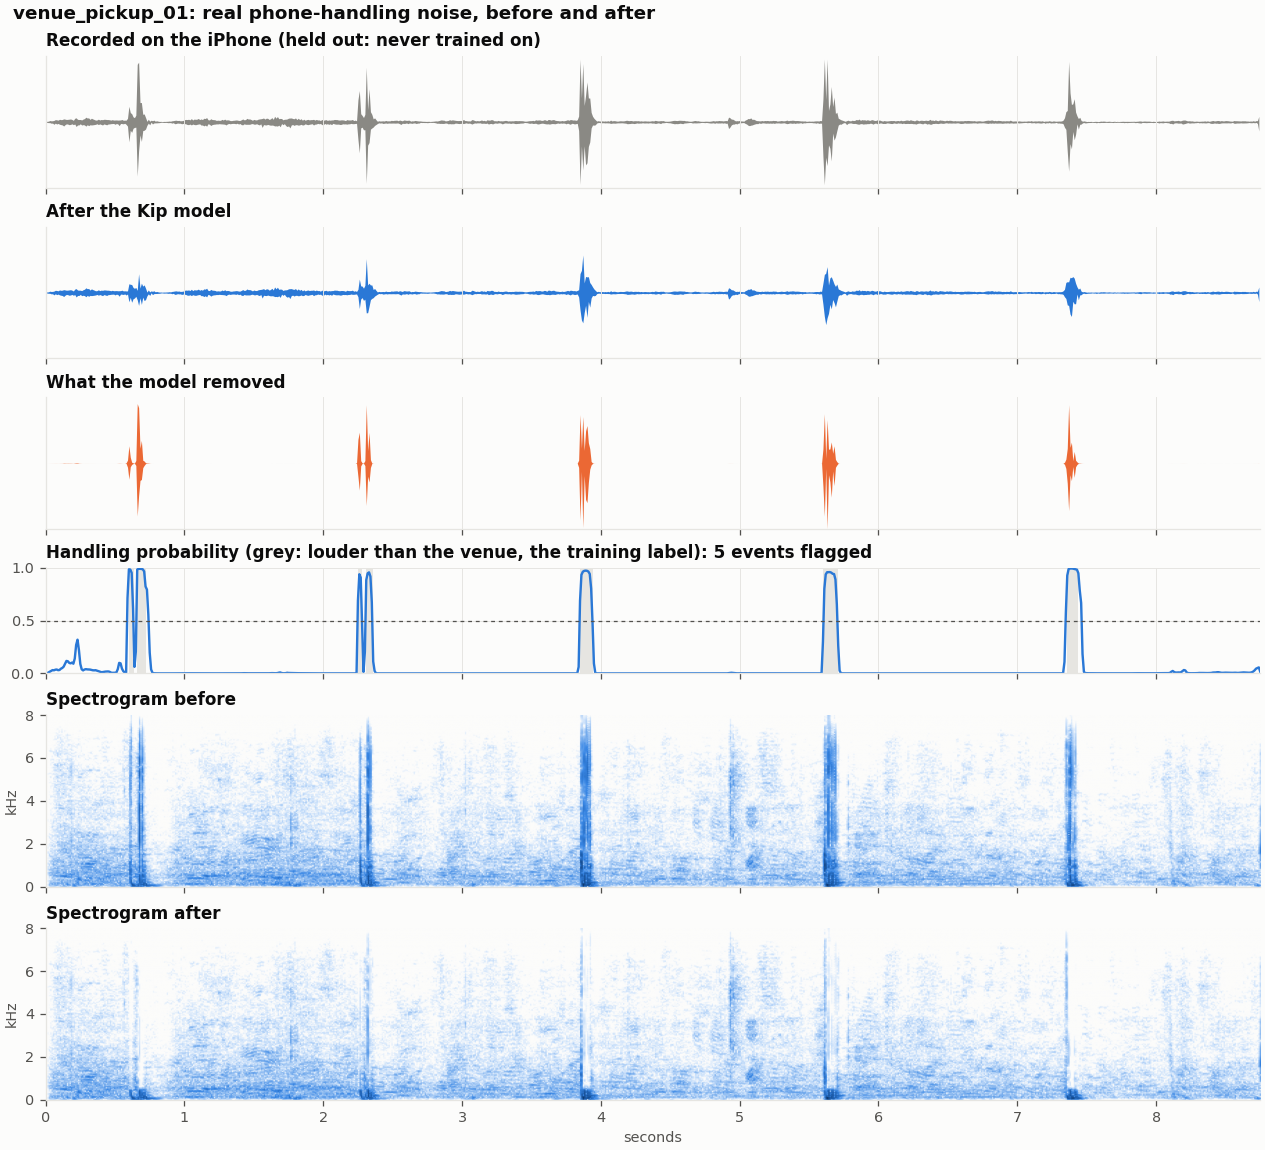

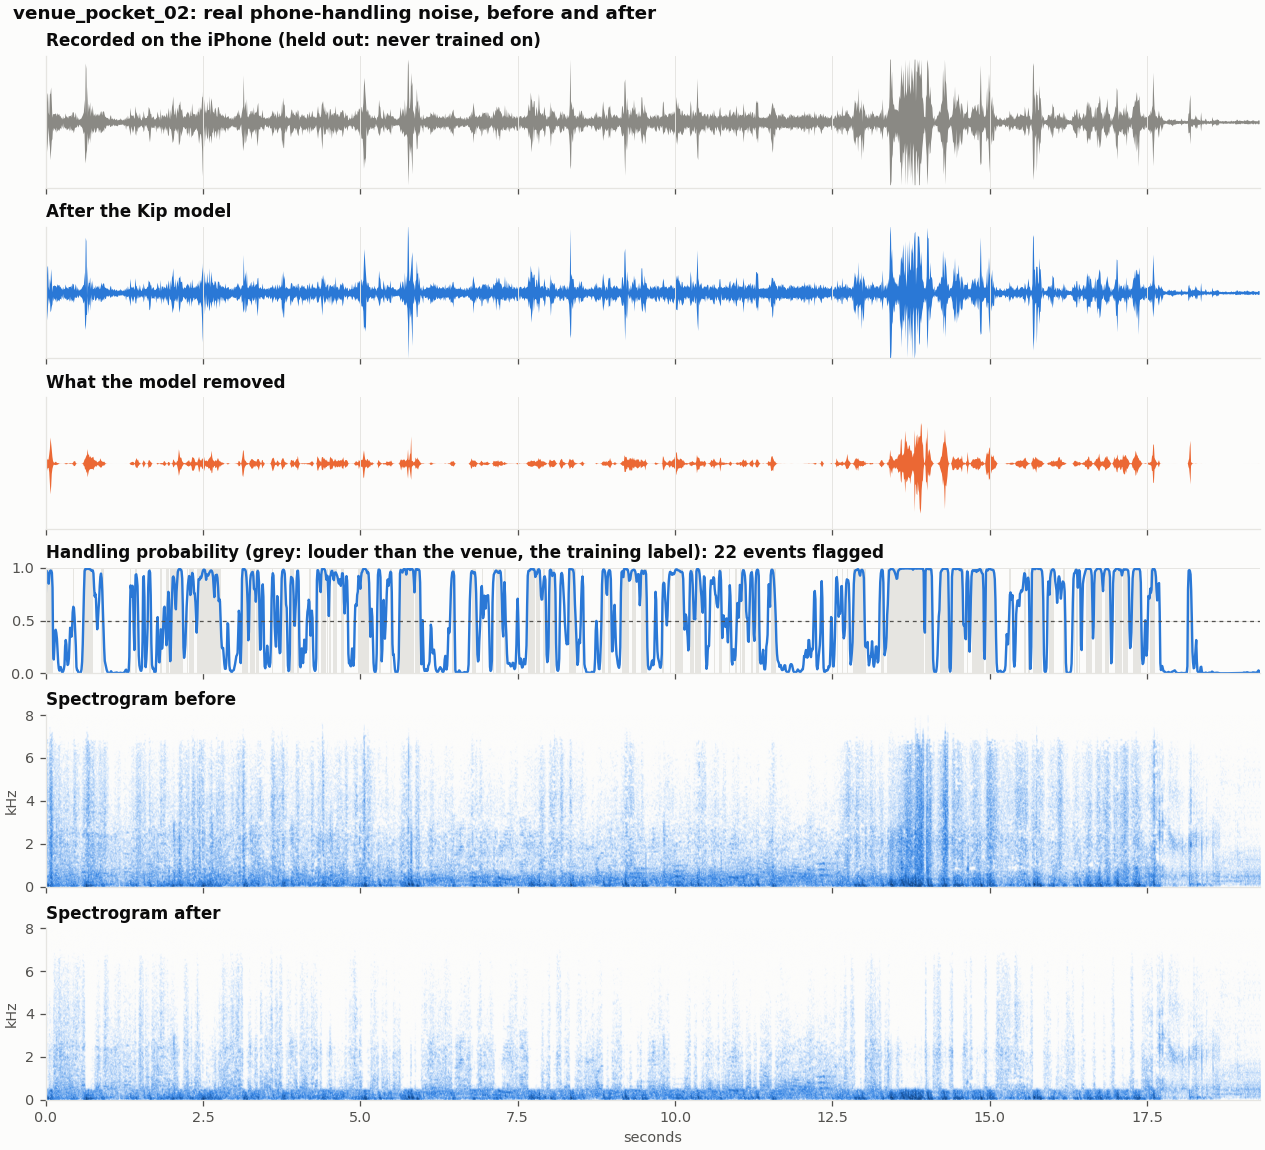

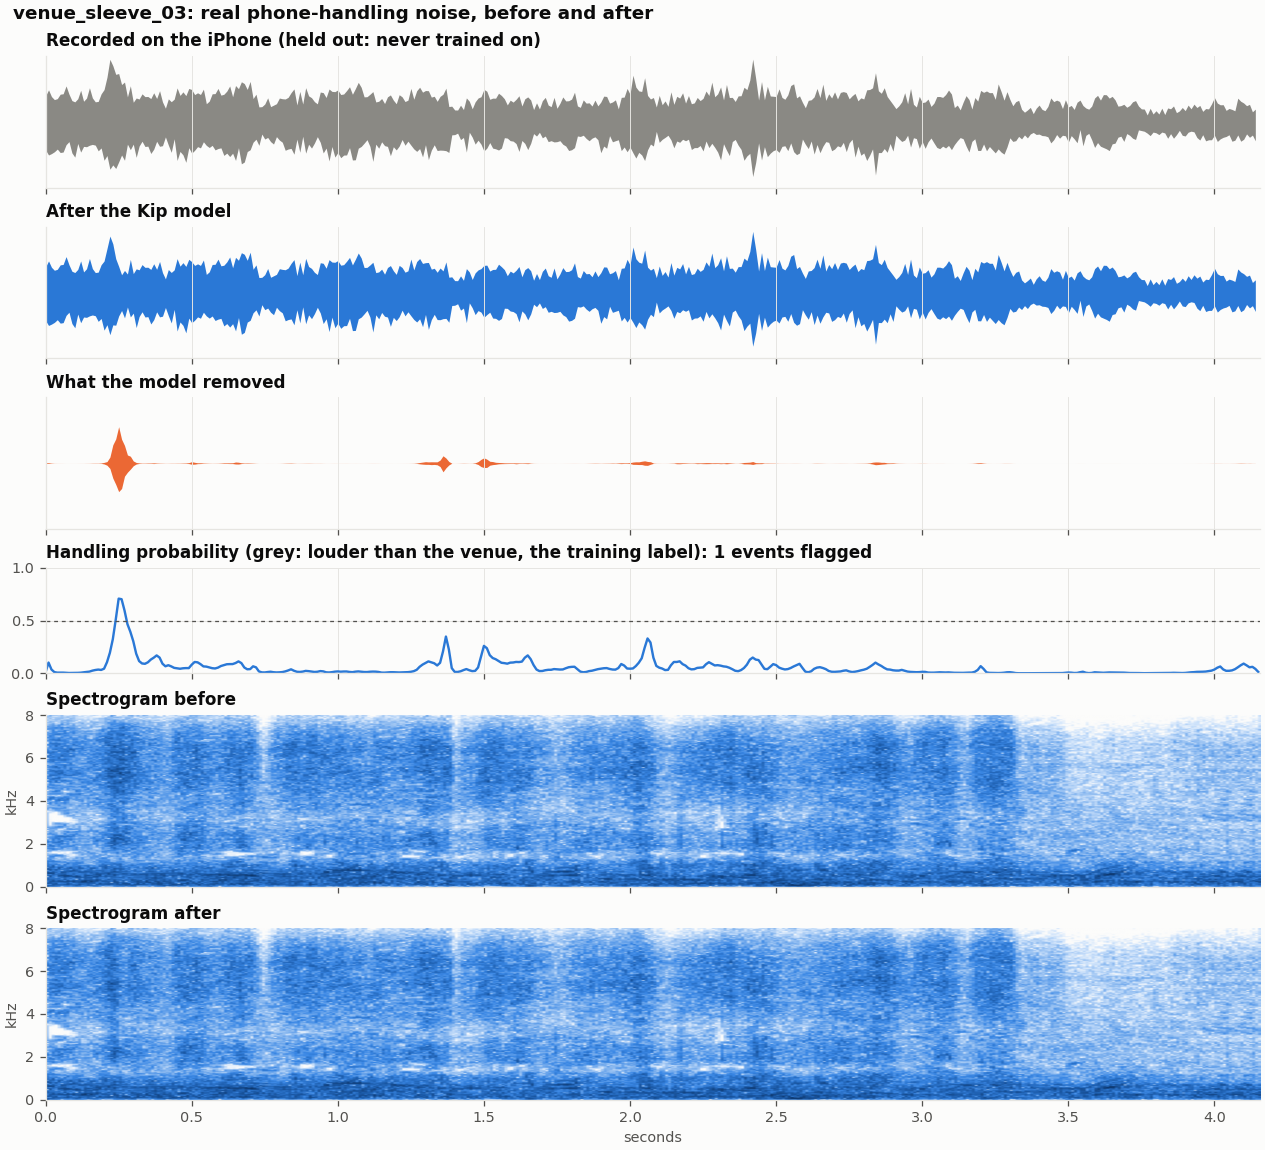

Listen: `venue_pickup_01` [before](../reports/handling-poc/audio/venue_pickup_01_input.wav), then [after](../reports/handling-poc/audio/venue_pickup_01_kip.wav)

In [7]:
rows = []
for name, s in summaries.items():
    for take, v in s["real_takes"].items():
        rows.append(f"| {name} | `{take}` | {v['handling_s']} s | {v['flagged_s']} s | {v['precision']} / {v['recall']} | "
                    f"{v['removed_on_handling_db']} dB | {v['removed_elsewhere_db']} dB |")
display(Markdown("| Model | Take | Handling (label) | Flagged | Precision / recall | Removed on handling | Removed elsewhere |\n"
                 "|---|---|---|---|---|---|---|\n" + "\n".join(rows)))
for png in sorted(folder.glob("real_*.png")):
    display(Image(filename=str(png)))
rel = Path("..") / "reports" / best / "audio"
display(Markdown(f"Listen: `venue_pickup_01` [before]({rel}/venue_pickup_01_input.wav), then [after]({rel}/venue_pickup_01_kip.wav)"))
display(Audio(url=f"{rel}/venue_pickup_01_input.wav")); display(Audio(url=f"{rel}/venue_pickup_01_kip.wav"))

## 6. Try it on any recording

Point this at any file from any device (an iPhone Voice Memo `.m4a` works): it prints the flagged moments and
writes `<name>.clean.wav` next to it. Same as `uv run python -m kipml.infer <file>` from the `ml/` folder.

In [8]:
from kipml.audio import load_any
from kipml.infer import segments

checkpoint = ML / "checkpoints" / ("handling-gpu.pt" if (ML / "checkpoints" / "handling-gpu.pt").exists() else "handling-poc.pt")
model = load_model(checkpoint)
print(f"{checkpoint.name}: {count_params(model):,} parameters")

recording = AUDIO / "ours" / "venue_pickup_02.wav"      # <- change me (this take was used in training)
x = load_any(recording)
clean, prob = enhance(model, x)
for s, e in segments(prob, 0.5, min_s=0.03):
    print(f"handling {s:6.2f} to {e:6.2f} s")
out = ML / "notebooks" / "output" / f"{recording.stem}.clean.wav"
out.parent.mkdir(exist_ok=True)
from kipml.audio import write_wav
write_wav(out, clean)
print("cleaned audio:", out.relative_to(ML))

handling-poc.pt: 217,218 parameters
handling   0.88 to   1.02 s
handling   2.49 to   2.59 s
handling   4.08 to   4.17 s
handling   5.58 to   5.74 s
handling   6.87 to   6.92 s
handling   7.89 to   7.93 s
handling   8.90 to   9.06 s
handling  10.17 to  10.23 s
handling  11.59 to  11.70 s
handling  13.69 to  13.93 s
handling  15.33 to  15.39 s
handling  16.73 to  16.82 s
handling  18.05 to  18.20 s
cleaned audio: notebooks/output/venue_pickup_02.clean.wav


## Limits, honestly

- **Small, single-venue data**: about 3 minutes of real handling noise from one phone in one noisy hall, plus
  synthetic placeholders and ESC-50 backgrounds. Expect it to be best on that phone and that kind of room.
- **Detection is the strong part.** On the held-out drop take it flags the five drops and almost nothing else.
  Suppression on raw takes is modest; flagging the frame is what Kip needs (a flagged spike is never linked to a
  wake-up), and cleaner removal needs more and more varied recordings.
- **Quiet handling is not labelled**: sleeve rubbing that is not louder than the venue counts as room, by design.
- **Licences**: ESC-50 is CC BY-NC 3.0, fine for this prototype only. Our recordings were speech-checked before
  committing; recordings with other people's conversation never leave our machines.